# Notebook 04 · Módulo 3: Detector de ritmo (fibrilación auricular)

**Proyecto #7 · Detección de arritmias en tiempo real con TinyML**

**Pregunta:** dado **un tramo de señal** (una ventana de varios segundos), ¿hay **fibrilación auricular**?

La diferencia con el notebook 03 es la **unidad de análisis**:

| | Notebook 03 (latidos) | Este notebook (ritmo) |
|---|---|---|
| Cada fila es... | **un latido** | **una ventana** de 30 s |
| Lo que mira | la **forma** de un latido | qué tan **desordenados** están los R–R de muchos latidos |
| Etiqueta | tipo de latido | ritmo del tramo (FA o no) |
| Base | MIT-BIH Arrhythmia | **MIT-BIH AF** (entrenar) y **CinC 2017** (probar con otro aparato) |

| Lo que pide tu doctora | En este módulo |
|---|---|
| **Etiquetas** | Tramos de ritmo de MIT-BIH AF; etiqueta por registro en CinC 2017 |
| **Métricas** | Se, Sp, PPV y F1 **por ventana** |
| **Validación** | **Por paciente** dentro de MIT-BIH AF (5 grupos) y externa en **CinC 2017** |

In [1]:
%pip install -q wfdb numpy pandas scipy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


**Para correr en Kaggle:** este notebook usa `ecg_comun.py`. Agrégalo como *Input* (tu dataset que lo contiene) y activa **Internet**. La celda de abajo lo copia junto al notebook.

In [2]:
from pathlib import Path
import shutil

if not Path("ecg_comun.py").exists():
    entradas = Path("/kaggle/input")
    encontrados = list(entradas.rglob("ecg_comun.py")) if entradas.exists() else []
    if not encontrados:
        raise FileNotFoundError("No encuentro ecg_comun.py: agrégalo con Add Input (el dataset donde lo subiste)")
    shutil.copy(encontrados[0], "ecg_comun.py")
    print("✓ ecg_comun.py copiado desde", encontrados[0])
else:
    print("✓ ecg_comun.py ya está junto al notebook")


✓ ecg_comun.py copiado desde /kaggle/input/datasets/lourdesgarcagarfias/cinc2017-proyecto7/cinc2017-proyecto7/ecg_comun.py


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import ecg_comun as ec

DATOS = Path("datos")
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True
ec.descargar_base("afdb", DATOS / "afdb")
ec.descargar_cinc2017(DATOS / "cinc2017")

Descargando afdb en datos/afdb (puede tardar varios minutos)...
Generating record list for: 00735
Generating record list for: 03665
Generating record list for: 04015
Generating record list for: 04043
Generating record list for: 04048
Generating record list for: 04126
Generating record list for: 04746
Generating record list for: 04908
Generating record list for: 04936
Generating record list for: 05091
Generating record list for: 05121
Generating record list for: 05261
Generating record list for: 06426
Generating record list for: 06453
Generating record list for: 06995
Generating record list for: 07162
Generating record list for: 07859
Generating record list for: 07879
Generating record list for: 07910
Generating record list for: 08215
Generating record list for: 08219
Generating record list for: 08378
Generating record list for: 08405
Generating record list for: 08434
Generating record list for: 08455
Generating list of all files for: 00735
Generating list of all files for: 03665
Genera

[ok] descarga terminada


## 1. Decisiones de este notebook

In [4]:
VENTANA_S = 30          # largo de cada ventana (s). Más larga = más confiable, pero tarda más en avisar
MIN_FRACCION_FA = 0.5   # una ventana es "FA" si al menos la mitad de su tiempo está anotado como FA
RR_MIN, RR_MAX = 0.25, 2.5   # R–R fuera de este rango (s) se descartan como artefactos
MIN_LATIDOS = 10        # ventanas con menos latidos válidos se descartan
K_VECINOS = 15
SEMILLA = 42

## 2. Medidas de "desorden" de los R–R

Cada ventana se resume en 6 números. Todos son **fáciles de calcular en el Arduino** (sumas, restas, una raíz):

| Medida | Qué mide | En FA... |
|---|---|---|
| `fc` | frecuencia cardiaca promedio (lpm) | suele subir |
| `cv` | desviación estándar ÷ promedio de los R–R | **sube** (R–R desparramados) |
| `rmssd_n` | qué tanto cambia un R–R respecto al anterior (normalizado) | **sube** |
| `pnn50` | fracción de cambios entre R–R consecutivos mayores a 50 ms | **sube** |
| `madn` | desviación típica "robusta" (ignora valores raros) | **sube** |
| `tpr` | fracción de puntos de giro (sube-baja-sube) | se acerca a 2/3, como algo **al azar** |

In [5]:
NOMBRES = ["fc", "cv", "rmssd_n", "pnn50", "madn", "tpr"]

def medidas_rr(rr):
    rr = rr[(rr > RR_MIN) & (rr < RR_MAX)]
    if len(rr) < MIN_LATIDOS:
        return None
    d = np.diff(rr)
    giros = np.sum((rr[1:-1] - rr[:-2]) * (rr[1:-1] - rr[2:]) > 0)
    return [60 / rr.mean(),
            rr.std() / rr.mean(),
            np.sqrt(np.mean(d ** 2)) / rr.mean(),
            np.mean(np.abs(d) > 0.05),
            np.median(np.abs(rr - np.median(rr))) / np.median(rr),
            giros / (len(rr) - 2)]

## 3. Construir la tabla de ventanas (MIT-BIH AF)

Para cada registro: partimos el tiempo en ventanas de 30 s **sin traslape**, tomamos los R de esa ventana (archivo `.qrs`), calculamos las 6 medidas y la etiqueta (qué fracción de la ventana estaba anotada como `AFIB`).

Los ritmos `AFL` (flutter) y `J` (unión) quedan como **"no FA"**: son justo los ritmos que podrían confundirse y generar falsas alarmas, así que conviene que el modelo los vea.

In [6]:
def ventanas_de_registro(carpeta, nombre, ext_latidos="qrs"):
    h = wfdb.rdheader(str(Path(carpeta) / nombre))
    r = wfdb.rdann(str(Path(carpeta) / nombre), ext_latidos).sample
    tramos = ec.leer_ritmos(carpeta, nombre, h.sig_len)
    etiquetas = sorted({et for _, _, et in tramos}) + ["(sin anotar)"]
    codigo = np.full(h.sig_len, len(etiquetas) - 1, dtype=np.int16)   # ritmo de cada muestra, como número
    for ini, fin, et in tramos:
        codigo[ini:fin] = etiquetas.index(et)
    es_fa = codigo == (etiquetas.index("AFIB") if "AFIB" in etiquetas else -1)
    paso = int(VENTANA_S * h.fs)
    filas = []
    for a in range(0, h.sig_len - paso + 1, paso):
        rr = np.diff(r[(r >= a) & (r < a + paso)]) / h.fs
        m = medidas_rr(rr)
        if m is None:
            continue
        mayoritario = etiquetas[np.bincount(codigo[a:a + paso]).argmax()]
        filas.append([nombre, a / h.fs, es_fa[a:a + paso].mean(), mayoritario, *m])
    return pd.DataFrame(filas, columns=["registro", "inicio_s", "fraccion_fa", "ritmo", *NOMBRES])

tabla = pd.concat([ventanas_de_registro(DATOS / "afdb", n) for n in ec.listar_registros(DATOS / "afdb")],
                  ignore_index=True)
tabla["y"] = (tabla.fraccion_fa >= MIN_FRACCION_FA).astype(int)
print(f"{len(tabla)} ventanas de {VENTANA_S} s de {tabla.registro.nunique()} pacientes")
display(tabla.groupby("ritmo").y.agg(ventanas="count", son_FA="sum"))
display(tabla.head())

27477 ventanas de 30 s de 23 pacientes


,ventanas,son_FA
ritmo,,
AFIB,10986,10986
AFL,168,0
J,9,0
N,16314,0


,registro,inicio_s,fraccion_fa,ritmo,fc,cv,rmssd_n,pnn50,madn,tpr,y
0,04015,0.0,0.0,N,92.187927,0.297663,0.306284,0.636364,0.287671,0.627907,0
1,04015,30.0,0.0,N,80.677693,0.261753,0.326324,0.538462,0.125000,0.710526,0
2,04015,60.0,0.0,N,92.630712,0.287806,0.396112,0.750000,0.100719,0.627907,0
3,04015,90.0,0.0,N,90.577166,0.337826,0.389717,0.833333,0.228571,0.585366,0
4,04015,120.0,0.0,N,85.446901,0.311486,0.427200,0.829268,0.149007,0.525000,0


## 4. Explorar: ¿qué medidas separan mejor?

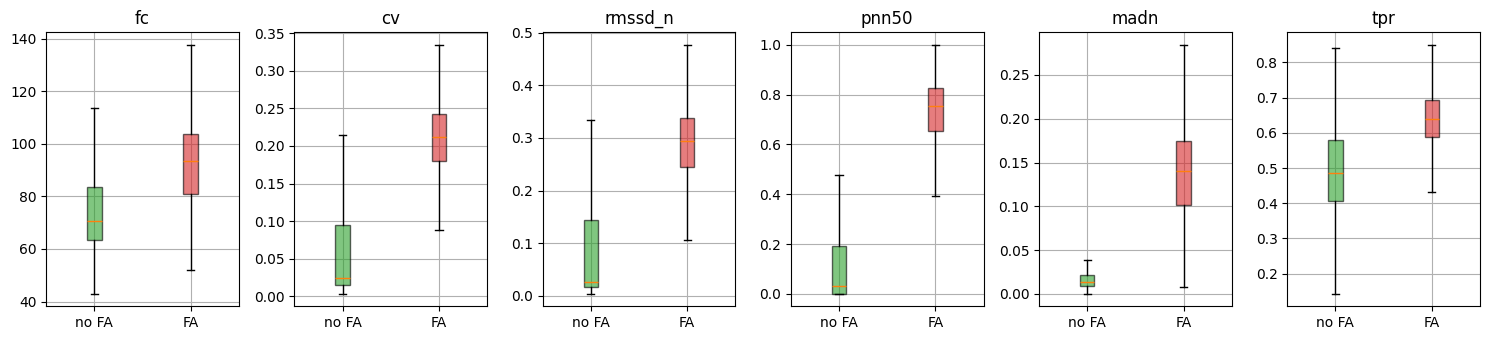

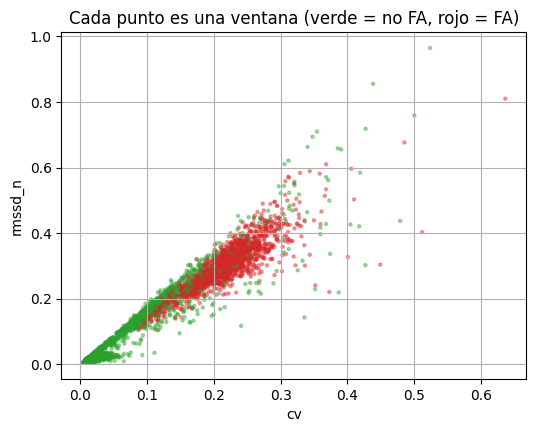

In [7]:
fig, ax = plt.subplots(1, len(NOMBRES), figsize=(15, 3.5))
for eje, col in zip(ax, NOMBRES):
    cajas = eje.boxplot([tabla[tabla.y == 0][col], tabla[tabla.y == 1][col]], showfliers=False,
                        patch_artist=True)
    for caja, color in zip(cajas["boxes"], ["tab:green", "tab:red"]):
        caja.set_facecolor(color); caja.set_alpha(0.6)
    eje.set_xticks([1, 2]); eje.set_xticklabels(["no FA", "FA"]); eje.set_title(col)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4.5))
muestra = tabla.sample(min(4000, len(tabla)), random_state=SEMILLA)
plt.scatter(muestra.cv, muestra.rmssd_n, c=muestra.y.map({0: "tab:green", 1: "tab:red"}), s=5, alpha=0.4)
plt.xlabel("cv"); plt.ylabel("rmssd_n"); plt.title("Cada punto es una ventana (verde = no FA, rojo = FA)")
plt.show()

**Cómo leerlo:** en las cajas, si la caja verde y la roja **no se enciman**, esa medida separa bien. En la nube de puntos, cada punto es una ventana de 30 s: si los rojos y verdes forman grupos separados (*clusters*), un modelo sencillo bastará.

## 5. Tres modelos, de más simple a más complejo

1. **Dummy**: siempre dice "no FA" (la línea base mínima).
2. **Regla de un umbral**: "si `cv` > umbral → FA". El umbral se elige con los datos de entrenamiento. Es lo más fácil de poner en un Arduino.
3. **kNN** con las 6 medidas (escaladas, como en la guía).

Validación **por paciente** con `GroupKFold` (5 grupos): ningún paciente está a la vez en entrenamiento y prueba.

Umbral de cv elegido en cada grupo: [0.11  0.112 0.146 0.143 0.109]
Dummy (siempre no FA):  Se = 0.0 %   Sp = 100.0 %   PPV = 0.0 %   F1 = 0.00
Regla: cv > umbral:  Se = 90.1 %   Sp = 81.5 %   PPV = 76.4 %   F1 = 0.83


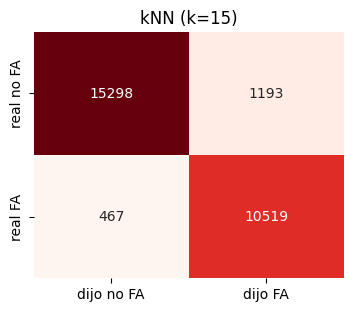

kNN (k=15):  Se = 95.7 %   Sp = 92.8 %   PPV = 89.8 %   F1 = 0.93


,Se %,Sp %,PPV %,F1
Dummy (siempre no FA),0.00,100.00,0.00,0.00
Regla: cv > umbral,90.11,81.46,76.41,0.83
kNN (k=15),95.75,92.77,89.81,0.93


In [8]:
def evaluar(y_real, y_pred, titulo="", graficar=True):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    m = {"Se %": 100 * vp / (vp + fn) if vp + fn else np.nan,
         "Sp %": 100 * vn / (vn + fp) if vn + fp else np.nan,
         "PPV %": 100 * vp / (vp + fp) if vp + fp else 0.0,
         "F1": f1_score(y_real, y_pred, zero_division=0)}
    if graficar:
        plt.figure(figsize=(4, 3.2))
        sns.heatmap([[vn, fp], [fn, vp]], annot=True, fmt="d", cmap="Reds", cbar=False,
                    xticklabels=["dijo no FA", "dijo FA"], yticklabels=["real no FA", "real FA"])
        plt.grid(False); plt.title(titulo); plt.show()
    print(f"{titulo}:  Se = {m['Se %']:.1f} %   Sp = {m['Sp %']:.1f} %   PPV = {m['PPV %']:.1f} %   F1 = {m['F1']:.2f}")
    return m


class ReglaUmbral:
    # Dice FA si una sola medida supera un umbral; elige el umbral que da mejor F1 en entrenamiento.
    def __init__(self, medida="cv"):
        self.col = NOMBRES.index(medida)
    def fit(self, X, y):
        candidatos = np.quantile(X[:, self.col], np.linspace(0.01, 0.99, 99))
        self.umbral = max(candidatos, key=lambda u: f1_score(y, X[:, self.col] > u, zero_division=0))
        return self
    def predict(self, X):
        return (X[:, self.col] > self.umbral).astype(int)


X = tabla[NOMBRES].to_numpy(); y = tabla.y.to_numpy(); grupos = tabla.registro.to_numpy()
modelos = {
    "Dummy (siempre no FA)": lambda: DummyClassifier(strategy="most_frequent"),
    "Regla: cv > umbral": lambda: ReglaUmbral("cv"),
    f"kNN (k={K_VECINOS})": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(K_VECINOS)),
}
pred_fuera = {nombre: np.zeros(len(y), dtype=int) for nombre in modelos}
umbrales = []
for entrena, prueba in GroupKFold(n_splits=5).split(X, y, grupos):
    for nombre, crear in modelos.items():
        m = crear().fit(X[entrena], y[entrena])
        pred_fuera[nombre][prueba] = m.predict(X[prueba])
        if isinstance(m, ReglaUmbral):
            umbrales.append(m.umbral)
print("Umbral de cv elegido en cada grupo:", np.round(umbrales, 3))

resultados = {nombre: evaluar(y, p, nombre, graficar=nombre.startswith("kNN")) for nombre, p in pred_fuera.items()}
display(pd.DataFrame(resultados).T.round(2))

**Cómo leerlo:** cada ventana se predijo con un modelo que **nunca vio a ese paciente**. Si la regla de un solo umbral queda cerca del kNN, es una gran noticia para el Arduino: se puede empezar con algo muy simple.

## 6. ¿Dónde se equivoca?

In [9]:
mejor = f"kNN (k={K_VECINOS})"
tabla["pred"] = pred_fuera[mejor]
errores = tabla.groupby("ritmo").agg(ventanas=("pred", "size"), porcentaje_que_dijo_FA=("pred", "mean"))
errores["porcentaje_que_dijo_FA"] = (100 * errores.porcentaje_que_dijo_FA).round(1)
display(errores)

tabla["acierto_FA"] = np.where(tabla.y == 1, tabla.pred, np.nan)       # solo cuenta en ventanas con FA
tabla["falsa_alarma"] = ((tabla.pred == 1) & (tabla.y == 0)).astype(int)
por_paciente = tabla.groupby("registro").agg(ventanas_FA=("y", "sum"), Se=("acierto_FA", "mean"),
                                             falsas_alarmas=("falsa_alarma", "sum"))
por_paciente["Se"] = (100 * por_paciente.Se).round(1)
display(por_paciente.rename(columns={"Se": "Se %"}))

,ventanas,porcentaje_que_dijo_FA
ritmo,,
AFIB,10986,95.7
AFL,168,42.9
J,9,22.2
N,16314,6.9


,ventanas_FA,Se %,falsas_alarmas
registro,,,
04015,7,100.0,92
04043,266,90.6,20
04048,13,76.9,5
04126,45,97.8,77
04746,651,99.5,1
04908,102,100.0,28
04936,882,88.5,70
05091,1,100.0,5
05121,773,91.5,22


**Cómo leerlo:** en la primera tabla, para `AFIB` quieres un % alto; para `N`, `AFL` y `J`, uno bajo. Si `AFL` sale alto, el modelo confunde flutter con FA (es un error "entendible": ambos son arritmias auriculares).

## 7. Validación externa: CinC 2017 (otro aparato, otra gente)

Ahora el reto de verdad:
- Entrenamos con **todas** las ventanas de MIT-BIH AF.
- Probamos en CinC 2017, que viene de un aparato **de mano** a 300 Hz y **no trae R anotados**: los encontramos con **nuestro detector** del notebook 02 (así es como funcionará en el Arduino).
- Cada registro de CinC (9–60 s) se trata como **una ventana**.

Usamos `N` (normal) y `A` (FA) para medir Se y Sp. Esta celda tarda unos minutos (son 8,528 registros). Los `O` (otros ritmos) los usamos aparte para ver **cuántas falsas alarmas** da el modelo con ritmos que no son FA.

275 registros sin suficientes latidos detectados (se descartan)


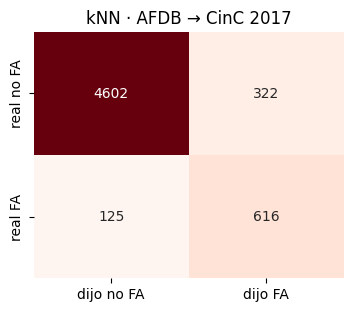

kNN · AFDB → CinC 2017:  Se = 83.1 %   Sp = 93.5 %   PPV = 65.7 %   F1 = 0.73
Regla cv · AFDB → CinC 2017:  Se = 84.5 %   Sp = 72.0 %   PPV = 31.3 %   F1 = 0.46

% de registros que el modelo marcó como FA, por etiqueta real:


,pred_knn,pred_regla
etiqueta,,
A,83.1,84.5
N,6.5,28.0
O,18.9,50.8
~,64.7,98.7


In [10]:
modelo_final = modelos[mejor]().fit(X, y)
regla_final = ReglaUmbral("cv").fit(X, y)

cinc = ec.leer_etiquetas_cinc2017(DATOS / "cinc2017")
filas = []
for _, fila in cinc.iterrows():
    x, fs = ec.leer_senal_cinc2017(fila.ruta)
    x = ec.remuestrear(x, fs, ec.FS)
    r = ec.detectar_picos_r(x, ec.FS)
    m = medidas_rr(np.diff(r) / ec.FS)
    filas.append([fila.registro, fila.etiqueta, *(m if m is not None else [np.nan] * len(NOMBRES))])
tabla_cinc = pd.DataFrame(filas, columns=["registro", "etiqueta", *NOMBRES])
sin_medidas = tabla_cinc[NOMBRES].isna().any(axis=1)
print(f"{sin_medidas.sum()} registros sin suficientes latidos detectados (se descartan)")
tabla_cinc = tabla_cinc[~sin_medidas].reset_index(drop=True)

Xc = tabla_cinc[NOMBRES].to_numpy()
tabla_cinc["pred_knn"] = modelo_final.predict(Xc)
tabla_cinc["pred_regla"] = regla_final.predict(Xc)

na = tabla_cinc[tabla_cinc.etiqueta.isin(["N", "A"])]
y_c = (na.etiqueta == "A").astype(int).to_numpy()
externos = {
    "kNN · MIT-BIH AF → CinC 2017": evaluar(y_c, na.pred_knn.to_numpy(), "kNN · AFDB → CinC 2017"),
    "Regla cv · MIT-BIH AF → CinC 2017": evaluar(y_c, na.pred_regla.to_numpy(), "Regla cv · AFDB → CinC 2017", graficar=False),
}
print("\n% de registros que el modelo marcó como FA, por etiqueta real:")
display(tabla_cinc.groupby("etiqueta")[["pred_knn", "pred_regla"]].mean().mul(100).round(1))

In [11]:
comparacion = pd.DataFrame({**{f"{k} · por paciente (AFDB)": v for k, v in resultados.items() if not k.startswith("Dummy")},
                            **externos}).T.round(2)
display(comparacion)

,Se %,Sp %,PPV %,F1
Regla: cv > umbral · por paciente (AFDB),90.11,81.46,76.41,0.83
kNN (k=15) · por paciente (AFDB),95.75,92.77,89.81,0.93
kNN · MIT-BIH AF → CinC 2017,83.13,93.46,65.67,0.73
Regla cv · MIT-BIH AF → CinC 2017,84.48,72.03,31.25,0.46


**Cómo leerlo:** es normal que los números **bajen** en CinC 2017: otro aparato, otra gente, R encontrados por nuestro detector (con sus errores) y ventanas más cortas. La pregunta importante no es "¿bajó?", sino **"¿cuánto bajó?"**. Si baja poco, el detector **generaliza**. La fila `O` de la última tabla te dice cuántas falsas alarmas darías con otros ritmos irregulares (por ejemplo, muchas extrasístoles).

## 8. (Opcional) Long-Term AF como validación adicional

Long-Term AF tiene 84 pacientes con ~24 h cada uno (a 128 Hz). Es grande (~1.8 GB completa), así que aquí se bajan solo unos cuantos registros.

In [12]:
USAR_LTAF = False
N_REGISTROS_LTAF = 10

if USAR_LTAF:
    lista = wfdb.get_record_list("ltafdb")[:N_REGISTROS_LTAF]
    ec.descargar_base("ltafdb", DATOS / "ltafdb", registros=lista)
    tabla_lt = pd.concat([ventanas_de_registro(DATOS / "ltafdb", n, ext_latidos="atr")
                          for n in ec.listar_registros(DATOS / "ltafdb")], ignore_index=True)
    tabla_lt["y"] = (tabla_lt.fraccion_fa >= MIN_FRACCION_FA).astype(int)
    evaluar(tabla_lt.y.to_numpy(), modelo_final.predict(tabla_lt[NOMBRES].to_numpy()), "kNN · AFDB → Long-Term AF")
else:
    print("Long-Term AF desactivada (cambia USAR_LTAF = True para correrla)")

Long-Term AF desactivada (cambia USAR_LTAF = True para correrla)


---
# Conclusiones (escríbelas tú)

1. ¿Qué medida de R–R separa mejor la FA? ¿Basta con una regla de un umbral?
2. ¿Qué Se, Sp y PPV logró cada modelo validando por paciente?
3. ¿Con qué ritmos se confunde (AFL, J, normal con muchas extrasístoles)?
4. ¿Cuánto bajaron los números en CinC 2017? ¿Por qué crees que bajaron?
5. ¿Cuántas falsas alarmas da con los ritmos "Otro" de CinC 2017?
6. Prueba `VENTANA_S = 10`: ¿cuánto empeora? Es el precio de avisar más rápido.

*(escribe aquí)*

**Siguiente paso:** el notebook 05 usa los mismos R–R para las reglas de **bradicardia** y **taquicardia**.